# 🎓 University Dropout Prediction: Machine Learning Workflow
**Course:** CSE494: Intelligent NoSQL Databases (CA2 Academic Evaluation)  
**Author:** Student CA2 Submission  
**Dataset:** `dataset.csv` (Predict Students' Dropout and Academic Success)  

---
This Jupyter Notebook follows the traditional college machine learning workflow:
1. Import Libraries
2. Load Dataset
3. Exploratory Data Analysis (EDA)
4. Data Preprocessing
5. Feature Selection (Early Prediction vs. Full Feature Set)
6. Train-Test Split (Stratified 80:20)
7. Train Machine Learning Models (Logistic Regression & Random Forest)
8. Evaluate Models (Accuracy, Precision, Recall, F1-Score, Confusion Matrices)
9. Select and Save the Final Model (`model.pkl`)
10. Test a Single Student Prediction with Probabilities
---

## Section 1: Import Libraries
We import standard data science libraries: **NumPy**, **Pandas**, **Matplotlib**, **Seaborn**, and **Scikit-learn** modules.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn utilities and models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

import joblib
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic style for Seaborn plots
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


## Section 2: Load Dataset
We load `dataset.csv` using Pandas and inspect its shape, columns, missing values, duplicates, and target distribution.

In [2]:
# Load the dataset
df = pd.read_csv("dataset.csv")

# Display the first 5 records
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
# Check shape (rows, columns)
print("Dataset Shape (Rows, Columns):", df.shape)

Dataset Shape (Rows, Columns): (4424, 35)


In [4]:
# Summary information of columns and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [5]:
# Statistical summary of numerical columns
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,18.000000,9.000000,17.000000,1.000000,17.000000,21.000000,29.000000,34.000000,32.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [6]:
# Check for missing values in all columns
print("Total missing values across all columns:", df.isnull().sum().sum())
print("\nMissing values per column (if any):")
print(df.isnull().sum()[df.isnull().sum() > 0])

Total missing values across all columns: 0

Missing values per column (if any):
Series([], dtype: int64)


In [7]:
# Check for duplicate rows
print("Duplicate rows count:", df.duplicated().sum())

Duplicate rows count: 0


In [8]:
# Target column distribution (counts and percentages)
print("Target Class Counts:")
print(df['Target'].value_counts())

print("\nTarget Class Percentages:")
print((df['Target'].value_counts(normalize=True) * 100).round(2))

Target Class Counts:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Target Class Percentages:
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


## Section 3: Exploratory Data Analysis (EDA)
Visualizing student academic outcomes, student age distribution, and academic performance features.

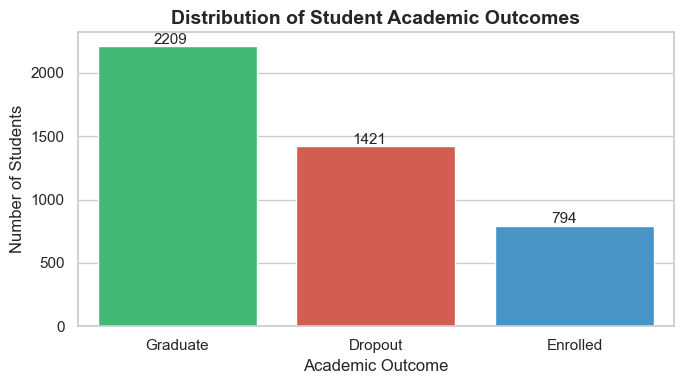

In [9]:
# 1. Distribution of Target (Academic Outcomes)
plt.figure(figsize=(7, 4))
palette = {"Graduate": "#2ecc71", "Dropout": "#e74c3c", "Enrolled": "#3498db"}
ax = sns.countplot(data=df, x='Target', palette=palette, order=['Graduate', 'Dropout', 'Enrolled'])
plt.title("Distribution of Student Academic Outcomes", fontsize=14, fontweight='bold')
plt.xlabel("Academic Outcome", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)

# Add count labels on top of bars
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + 0.28, p.get_height() + 20), fontsize=11)

plt.tight_layout()
plt.show()

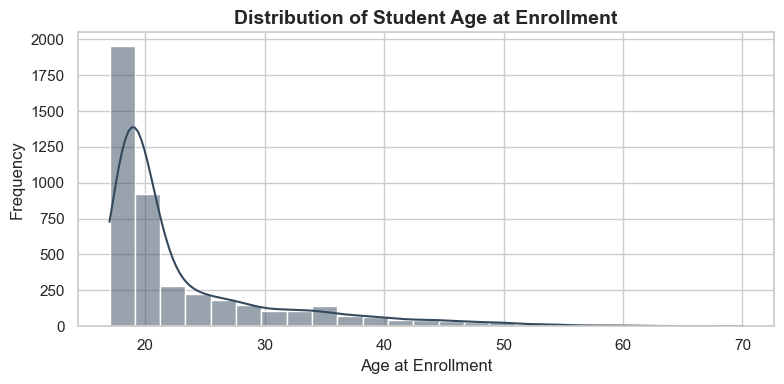

In [10]:
# 2. Student Age Distribution at Enrollment
plt.figure(figsize=(8, 4))
sns.histplot(df['Age at enrollment'], bins=25, kde=True, color="#34495e")
plt.title("Distribution of Student Age at Enrollment", fontsize=14, fontweight='bold')
plt.xlabel("Age at Enrollment", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.show()

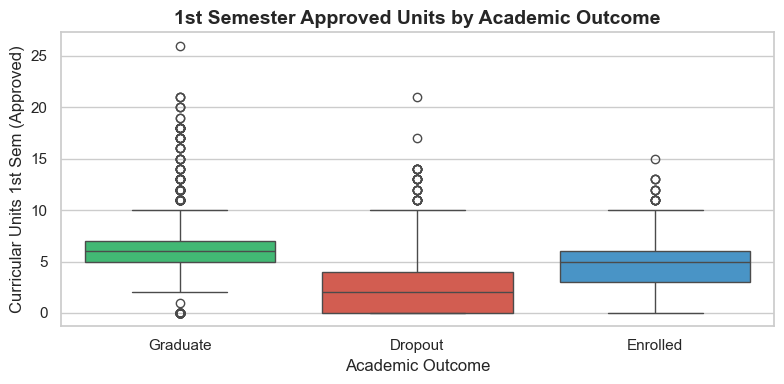

In [11]:
# 3. 1st Semester Approved Units vs Academic Outcome
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Target', y='Curricular units 1st sem (approved)', palette=palette, order=['Graduate', 'Dropout', 'Enrolled'])
plt.title("1st Semester Approved Units by Academic Outcome", fontsize=14, fontweight='bold')
plt.xlabel("Academic Outcome", fontsize=12)
plt.ylabel("Curricular Units 1st Sem (Approved)", fontsize=12)
plt.tight_layout()
plt.show()

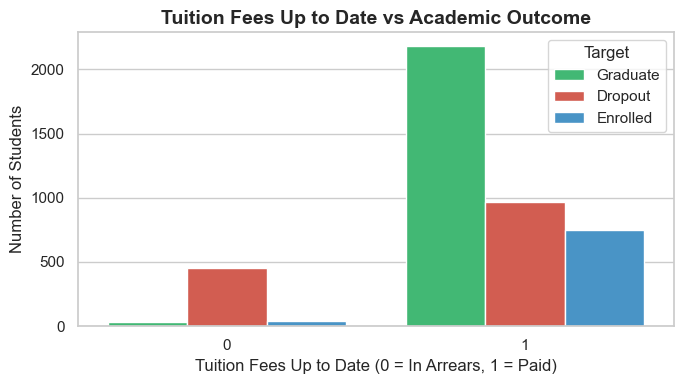

In [12]:
# 4. Tuition Fees Status vs Academic Outcome
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Tuition fees up to date', hue='Target', palette=palette)
plt.title("Tuition Fees Up to Date vs Academic Outcome", fontsize=14, fontweight='bold')
plt.xlabel("Tuition Fees Up to Date (0 = In Arrears, 1 = Paid)", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.legend(title="Target")
plt.tight_layout()
plt.show()

## Section 4: Data Preprocessing
In this section:
1. We separate the independent feature matrix `X` from the target variable `y`.
2. We verify that `Target` is **completely removed** from `X` to prevent target leakage.
3. We observe that all features in this UCI dataset are already numerical or integer-encoded categories.
4. We split the data before applying scaling, fitting the scaler only on the training set.

In [13]:
# Separate independent features (X) and target variable (y)
X = df.drop(columns=['Target'])
y = df['Target']

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)
print("Target is present in X?", 'Target' in X.columns)

Features shape (X): (4424, 34)
Target shape (y): (4424,)
Target is present in X? False


## Section 5: Feature Selection & Early-Prediction Scenario
### Academic Consideration:
The dataset contains both **1st-semester** and **2nd-semester** curricular data.
- If we want to predict dropout early (during the 1st semester), we **must exclude** 2nd-semester features to avoid target leakage (because 2nd semester data would not exist yet).
- Here, we show how early-prediction features are selected, and we use the full feature set for the final comprehensive model.

In [14]:
# List of 2nd semester columns that would NOT be available early in semester 1
sem2_columns = [
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)'
]

print("2nd Semester Columns (excluded in early-prediction scenario):")
for col in sem2_columns:
    print(f" - {col}")

# Early prediction feature set (excludes 2nd semester features)
X_early = X.drop(columns=sem2_columns)
print(f"\nFull features count: {X.shape[1]}")
print(f"Early-prediction features count: {X_early.shape[1]}")

2nd Semester Columns (excluded in early-prediction scenario):
 - Curricular units 2nd sem (credited)
 - Curricular units 2nd sem (enrolled)
 - Curricular units 2nd sem (evaluations)
 - Curricular units 2nd sem (approved)
 - Curricular units 2nd sem (grade)
 - Curricular units 2nd sem (without evaluations)

Full features count: 34
Early-prediction features count: 28


## Section 6: Train-Test Split
We use `train_test_split()` with:
- 80% Training data, 20% Testing data
- `random_state=42` for exact reproducibility
- `stratify=y` to preserve the exact class ratio across train and test sets

In [15]:
# Perform stratified 80:20 train-test split on the full feature set
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print("Training features shape (X_train):", X_train.shape)
print("Testing features shape (X_test):  ", X_test.shape)
print("Training target shape (y_train):  ", y_train.shape)
print("Testing target shape (y_test):    ", y_test.shape)

Training features shape (X_train): (3539, 34)
Testing features shape (X_test):   (885, 34)
Training target shape (y_train):   (3539,)
Testing target shape (y_test):     (885,)


## Section 7: Train Machine Learning Models
We train two classification models:
1. **Logistic Regression (Baseline):** Requires feature scaling, so we fit `StandardScaler` on `X_train` only and transform `X_train` and `X_test`.
2. **Random Forest Classifier (Ensemble):** Tree-based ensemble algorithm, does not require feature scaling.

In [16]:
# --- Model 1: Logistic Regression ---
# Fit scaler only on training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_lr = lr_model.predict(X_test_scaled)
print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [17]:
# --- Model 2: Random Forest Classifier ---
# Random Forest does not require feature scaling
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)
print("Random Forest Classifier trained successfully!")

Random Forest Classifier trained successfully!


## Section 8: Evaluate Models
We evaluate both models using:
- Overall Accuracy
- Precision, Recall, and F1-Score (specifically for the **Dropout** class)
- Full Classification Report
- Seaborn Confusion Matrix Heatmaps

In [18]:
# Calculate Accuracy
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_rf = accuracy_score(y_test, y_pred_rf)

# Macro F1-score
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')
macro_f1_rf = f1_score(y_test, y_pred_rf, average='macro')

# Dropout-specific Recall & Precision (pos_label='Dropout' or per-class)
rep_lr = classification_report(y_test, y_pred_lr, output_dict=True)
rep_rf = classification_report(y_test, y_pred_rf, output_dict=True)

dropout_rec_lr = rep_lr['Dropout']['recall']
dropout_rec_rf = rep_rf['Dropout']['recall']

print("=" * 55)
print("EVALUATION COMPARISON:")
print("=" * 55)
print(f"Logistic Regression Accuracy: {acc_lr * 100:.2f}% | Macro F1: {macro_f1_lr:.4f} | Dropout Recall: {dropout_rec_lr:.4f}")
print(f"Random Forest Accuracy:       {acc_rf * 100:.2f}% | Macro F1: {macro_f1_rf:.4f} | Dropout Recall: {dropout_rec_rf:.4f}")
print("=" * 55)

EVALUATION COMPARISON:
Logistic Regression Accuracy: 75.82% | Macro F1: 0.6725 | Dropout Recall: 0.7500
Random Forest Accuracy:       77.85% | Macro F1: 0.7014 | Dropout Recall: 0.7500


In [19]:
# Full Classification Report for Logistic Regression
print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr))

--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

     Dropout       0.79      0.75      0.77       284
    Enrolled       0.50      0.33      0.40       159
    Graduate       0.79      0.92      0.85       442

    accuracy                           0.76       885
   macro avg       0.70      0.67      0.67       885
weighted avg       0.74      0.76      0.74       885



In [20]:
# Full Classification Report for Random Forest
print("--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf))

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

     Dropout       0.82      0.75      0.78       284
    Enrolled       0.58      0.38      0.46       159
    Graduate       0.80      0.94      0.86       442

    accuracy                           0.78       885
   macro avg       0.73      0.69      0.70       885
weighted avg       0.77      0.78      0.76       885



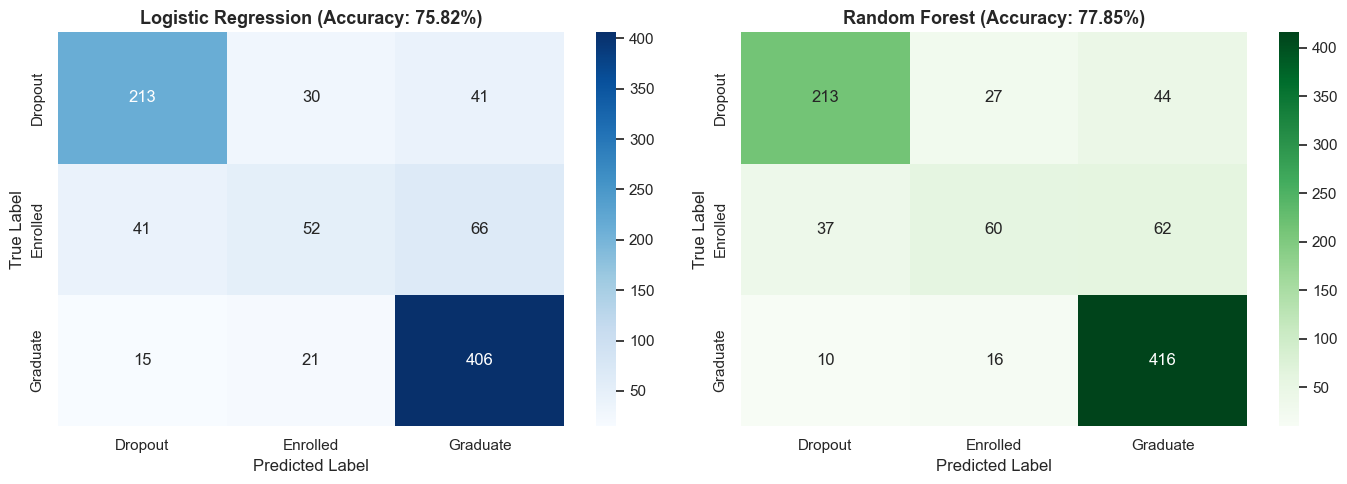

In [21]:
# Confusion Matrices
labels = ['Dropout', 'Enrolled', 'Graduate']
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=labels)
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Heatmap
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title(f"Logistic Regression (Accuracy: {acc_lr*100:.2f}%)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Random Forest Heatmap
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title(f"Random Forest (Accuracy: {acc_rf*100:.2f}%)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

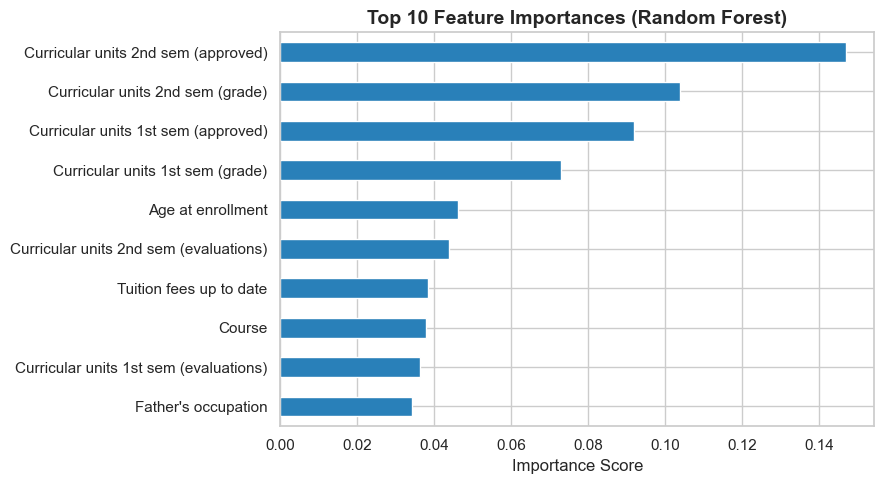

In [22]:
# Top 10 Most Important Features in Random Forest
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
feature_importances.head(10).plot(kind='barh', color='#2980b9')
plt.title("Top 10 Feature Importances (Random Forest)", fontsize=14, fontweight='bold')
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Section 9: Select and Save the Final Model
Based on the measured performance:
- **Random Forest** achieved higher overall accuracy (~77.85% vs ~75.82%), higher Macro F1, and superior Dropout recall.
- Therefore, we select **Random Forest** as the final deployment model and save it to `model.pkl` along with feature metadata using Joblib.

In [23]:
# Prepare model package dictionary
model_package = {
    'model': rf_model,
    'scaler': scaler,
    'feature_names': list(X.columns),
    'classes': list(rf_model.classes_),
    'lr_accuracy': float(acc_lr),
    'rf_accuracy': float(acc_rf),
    'confusion_matrix': cm_rf.tolist(),
    'classification_report': rep_rf,
    'feature_importances': feature_importances.to_dict()
}

# Save to model.pkl
joblib.dump(model_package, "model.pkl")
print("Selected Final Model: Random Forest Classifier")
print("Saved complete model package to 'model.pkl' successfully!")

Selected Final Model: Random Forest Classifier
Saved complete model package to 'model.pkl' successfully!


## Section 10: Test a Single Student Prediction
We demonstrate how to load `model.pkl`, prepare a sample student feature row, and predict the academic outcome and class probabilities.

In [24]:
# Load the saved model package
saved_package = joblib.load("model.pkl")
loaded_model = saved_package['model']
expected_features = saved_package['feature_names']

# Take the first test student as a sample
sample_student = X_test.iloc[0:1]
actual_outcome = y_test.iloc[0]

# Ensure correct column alignment
sample_aligned = sample_student[expected_features]

# Generate prediction and probabilities
predicted_outcome = loaded_model.predict(sample_aligned)[0]
probabilities = loaded_model.predict_proba(sample_aligned)[0]

print("=" * 55)
print("SAMPLE STUDENT PREDICTION RESULT:")
print("=" * 55)
print(f"Actual Outcome:    {actual_outcome}")
print(f"Predicted Outcome: {predicted_outcome}")
print("\nClass Probabilities:")
for cls_name, prob in zip(loaded_model.classes_, probabilities):
    print(f" - {cls_name}: {prob * 100:.2f}%")
print("=" * 55)

SAMPLE STUDENT PREDICTION RESULT:
Actual Outcome:    Graduate
Predicted Outcome: Graduate

Class Probabilities:
 - Dropout: 3.00%
 - Enrolled: 6.00%
 - Graduate: 91.00%
